# 🤖 Tarea 1 · Parte 2 — Del LLM al clasificador

**Flujo:** línea base zero-shot → etiquetado débil con un LLM local (Ollama) → auditoría
humana de 20 casos → split 70/15/15 → fine-tuning de un Transformer → evaluación en test →
comparativa y decisión.

## Decisión de diseño, explícita

El enunciado deja una ambigüedad importante: hay **dos etiquetas posibles** para entrenar.

| Columna | De dónde viene | Qué es |
|---|---|---|
| `etiqueta` | Sección del diario (notebook 1) | Referencia independiente, pero ruidosa: una nota sobre el presupuesto puede ir en `politica` en un diario y en `economia` en el otro |
| `etiqueta_llm` | LLM leyendo titular + bajada | La supervisión débil que pide el paso 2 |

**Se entrena con `etiqueta_llm`**, porque el enunciado pide explícitamente supervisión débil
con LLM. El test se evalúa contra `etiqueta_llm` (la métrica que va en el comentario de
entrega) y **además** contra `etiqueta`, que al no haber participado del entrenamiento
funciona como control externo. La brecha entre ambas cifras es uno de los hallazgos del
trabajo.

> 💡 Si tu laptop va lenta en el paso 5, este notebook corre igual en **Google Colab con GPU
> T4**: sube `datos/noticias.csv`, ejecútalo y descarga `modelo/` y `modelo/metricas.json`.

In [1]:
import json, os, platform, random, re, subprocess, time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import requests

SEED = 42
random.seed(SEED); np.random.seed(SEED)

BASE   = Path.cwd()
DATOS  = BASE / "datos"
MODELO = BASE / "modelo"; MODELO.mkdir(exist_ok=True)

CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
ID2LAB = dict(enumerate(CATEGORIAS))
LAB2ID = {v: k for k, v in ID2LAB.items()}

df = pd.read_csv(DATOS / "noticias.csv").fillna({"bajada": ""})
print("Dataset:", df.shape)
display(df["etiqueta"].value_counts())

# texto que ve el modelo: titular + bajada, que es mas senal que el titular solo
df["texto"] = (df["titular"].str.strip() + ". " + df["bajada"].str.strip()).str.strip(". ")

Dataset: (408, 7)


etiqueta
economia              127
politica              106
deportes              100
ciencia_tecnologia     75
Name: count, dtype: int64

## 0 · Detección de hardware

El profesor insistió en esto: por defecto todo cae a CPU y hay que decirle explícitamente
al código que use la GPU. Esta celda detecta **CUDA** (NVIDIA), **MPS** (Mac con Apple
Silicon) o CPU, y el resto del notebook usa ese dispositivo.

In [2]:
import torch

if torch.cuda.is_available():
    DEVICE, DEVICE_ID = "cuda", 0
    detalle = torch.cuda.get_device_name(0)
    vram = torch.cuda.get_device_properties(0).total_memory / 1e9
    detalle += f" ({vram:.1f} GB VRAM)"
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    DEVICE, DEVICE_ID = "mps", "mps"
    detalle = "Apple Silicon (Metal Performance Shaders)"
else:
    DEVICE, DEVICE_ID = "cpu", -1
    detalle = platform.processor() or "CPU"

print(f"Dispositivo : {DEVICE}")
print(f"Detalle     : {detalle}")
print(f"PyTorch     : {torch.__version__}")
if DEVICE == "cpu":
    print("\n  Aviso: sin GPU el fine-tuning toma entre 20 y 40 minutos con este dataset.")

Dispositivo : cpu
Detalle     : Intel64 Family 6 Model 154 Stepping 3, GenuineIntel
PyTorch     : 2.6.0+cpu

  Aviso: sin GPU el fine-tuning toma entre 20 y 40 minutos con este dataset.


## 1 · Línea base Zero-Shot (sin fine-tuning)

Es el **piso mínimo a superar**. Se evalúa sobre 40 titulares tomados al azar, de forma
estratificada para que las 4 categorías estén representadas.

En este punto del flujo las etiquetas del LLM todavía no existen, así que la referencia es
`etiqueta` (la sección del diario). En la tabla comparativa del paso 6 se vuelve a medir
todo contra una referencia común.

In [3]:
from transformers import pipeline

# El modelo grande (joeddav/xlm-roberta-large-xnli) ronda los 2.2 GB y es lento en laptop.
# El de Recognai es mucho mas liviano y es el otro que autoriza el enunciado.
MODELO_ZS = "Recognai/bert-base-spanish-wwm-cased-xnli"
# MODELO_ZS = "joeddav/xlm-roberta-large-xnli"   # alternativa si tienes VRAM de sobra

HIPOTESIS = "Esta noticia trata sobre {}."
ETIQUETAS_ES = {"politica": "politica", "economia": "economia",
                "deportes": "deportes", "ciencia_tecnologia": "ciencia y tecnologia"}
INV_ES = {v: k for k, v in ETIQUETAS_ES.items()}

indices = []
for _cat, grupo in df.groupby("etiqueta"):
    indices += list(grupo.sample(min(10, len(grupo)), random_state=SEED).index)
muestra_zs = df.loc[indices].reset_index(drop=True)
print("Muestra zero-shot:", len(muestra_zs), "titulares")
display(muestra_zs["etiqueta"].value_counts())

zs = pipeline("zero-shot-classification", model=MODELO_ZS, device=DEVICE_ID)

t0 = time.time()
pred_zs = []
for texto in muestra_zs["texto"]:
    r = zs(texto, candidate_labels=list(ETIQUETAS_ES.values()),
           hypothesis_template=HIPOTESIS, multi_label=False)
    pred_zs.append(INV_ES[r["labels"][0]])
dur_zs = time.time() - t0

muestra_zs["pred_zs"] = pred_zs
print(f"Tiempo: {dur_zs:.1f}s ({dur_zs/len(muestra_zs):.2f}s por titular)")

Muestra zero-shot: 40 titulares


etiqueta
ciencia_tecnologia    10
deportes              10
economia              10
politica              10
Name: count, dtype: int64

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Tiempo: 16.8s (0.42s por titular)


In [4]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

ACC_ZS = accuracy_score(muestra_zs["etiqueta"], muestra_zs["pred_zs"])
F1_ZS  = f1_score(muestra_zs["etiqueta"], muestra_zs["pred_zs"],
                  average="macro", labels=CATEGORIAS, zero_division=0)

print(f"ZERO-SHOT  ({MODELO_ZS})")
print(f"  Accuracy : {ACC_ZS:.3f}")
print(f"  F1 macro : {F1_ZS:.3f}   <- este es el piso minimo a superar\n")
print(classification_report(muestra_zs["etiqueta"], muestra_zs["pred_zs"],
                            labels=CATEGORIAS, zero_division=0))

ZERO-SHOT  (Recognai/bert-base-spanish-wwm-cased-xnli)
  Accuracy : 0.700
  F1 macro : 0.682   <- este es el piso minimo a superar

                    precision    recall  f1-score   support

          politica       0.45      1.00      0.62        10
          economia       1.00      0.70      0.82        10
          deportes       1.00      0.90      0.95        10
ciencia_tecnologia       1.00      0.20      0.33        10

          accuracy                           0.70        40
         macro avg       0.86      0.70      0.68        40
      weighted avg       0.86      0.70      0.68        40



### ¿Por qué un LLM generativo (Ollama) y no el clasificador de la Clase 2?

En la Clase 2 usamos `argilla/ModernBERT-domain-classifier`. ¿Por qué no reutilizarlo aquí, restringido a nuestras 4 categorías? Porque **no se puede**, y conviene entender el motivo:

- **Sus etiquetas están fijas en el modelo.** Fue afinado sobre `argilla/synthetic-domain-text-classification` (1 000 textos sintéticos **en inglés**) con **26 categorías cableadas en su capa de salida** (`business-and-industrial`, `sports`, `science`, `finance`, `law-and-government`…). No existe un parámetro para decirle "usa solo estas 4": un clasificador afinado siempre devuelve una de las clases con las que fue entrenado. Colapsar sus 26 clases inglesas a nuestras 4 (¿`law-and-government` + `people-and-society` → `politica`?) sería inventar un mapeo ruidoso y, encima, pedirle que clasifique titulares peruanos estando entrenado en inglés: fuera de distribución.

- **El modelo que sí acepta etiquetas arbitrarias ya es nuestra línea base.** El zero-shot (paso 1) convierte cada categoría en una hipótesis ("Esta noticia trata sobre economía") y mide implicación; por eso admite cualquier lista. Pero usarlo *también* para etiquetar sería circular: la tabla comparativa (paso 6) enfrenta zero-shot vs. LLM débil vs. Transformer, y el enunciado llama al zero-shot "el piso mínimo a superar". Si el etiquetador fuera el zero-shot, el Transformer solo podría aprender a reproducir sus errores — no se puede superar un piso que es también el techo.

- **El enunciado pide un LLM generativo** ("Usar un LLM: Ollama, Qwen local, Gemini API o similar"), que es justo lo que hizo el profesor en la Clase 2: definió sus propias categorías y delegó el etiquetado a un LLM (Haiku sobre repositorios de GitHub). Esta tarea es ese mismo flujo — el pipeline venía con las etiquetas puestas; aquí las fabricamos nosotros con supervisión débil.

> Consejo del profesor en clase: *"si quieren argumentar por qué el modelo que han utilizado es correcto, tienen que probar varios y de los varios elegir uno."* Esta celda documenta esa decisión.

**Decisión:** etiquetado con `qwen2.5:7b` vía Ollama (local, gratuito, en español), auditado a mano en 20 casos (más abajo).

## 2 · Supervisión débil: etiquetado con un LLM local (Ollama)

Todo corre en la máquina, sin API ni costo por consulta. Se le pide al modelo una respuesta
en **JSON estructurado** con la categoría y su confianza; `format="json"` de Ollama fuerza
que la salida sea JSON válido y evita tener que parsear texto libre.

**Antes de ejecutar:** `ollama serve` tiene que estar corriendo y el modelo descargado
(`ollama pull qwen2.5:7b`). La celda siguiente detecta qué modelos tienes.

In [5]:
OLLAMA = os.getenv("OLLAMA_HOST", "http://localhost:11434")

def modelos_ollama():
    try:
        r = requests.get(f"{OLLAMA}/api/tags", timeout=10)
        return [m["name"] for m in r.json().get("models", [])]
    except requests.RequestException as e:
        print(f"No se pudo contactar a Ollama en {OLLAMA}: {e}")
        print("Levantalo con:  ollama serve     y descarga un modelo:  ollama pull qwen2.5:7b")
        return []

disponibles = modelos_ollama()
print("Modelos disponibles:", disponibles or "(ninguno)")

PREFERIDOS = ["qwen2.5:7b", "qwen2.5", "qwen3", "llama3.1:8b", "llama3.1", "llama3", "gemma2", "mistral"]
MODELO_LLM = next((m for p in PREFERIDOS for m in disponibles if m.startswith(p)),
                  disponibles[0] if disponibles else "qwen2.5:7b")
print("Modelo elegido para el etiquetado:", MODELO_LLM)

Modelos disponibles: ['qwen2.5:7b', 'qwen2.5:3b', 'qwen2.5:latest', 'llama3.2:latest']
Modelo elegido para el etiquetado: qwen2.5:7b


In [6]:
PROMPT = """Eres un editor de un diario peruano. Clasifica la noticia en EXACTAMENTE una
de estas cuatro categorias:

- politica: gobierno, Congreso, elecciones, partidos, justicia, corrupcion, politica exterior
- economia: mercados, empleo, inflacion, empresas, comercio, finanzas publicas, mineria
- deportes: futbol, seleccion, clubes, atletas, torneos, resultados deportivos
- ciencia_tecnologia: investigacion cientifica, salud, espacio, ambiente, software, IA, gadgets

Responde SOLO con un JSON: {{"categoria": "...", "confianza": 0.0}}
La confianza va de 0 a 1 y refleja que tan seguro estas.

TITULAR: {titular}
BAJADA: {bajada}"""

def etiquetar(titular, bajada, modelo=None, reintentos=1):
    modelo = modelo or MODELO_LLM
    cuerpo = {
        "model": modelo,
        "prompt": PROMPT.format(titular=titular, bajada=(bajada or "")[:400]),
        "format": "json",
        "stream": False,
        "options": {"temperature": 0, "seed": SEED, "num_predict": 80},
    }
    for _ in range(reintentos + 1):
        try:
            r = requests.post(f"{OLLAMA}/api/generate", json=cuerpo, timeout=180)
            datos = json.loads(r.json()["response"])
            cat = str(datos.get("categoria", "")).strip().lower().replace(" ", "_")
            if cat in CATEGORIAS:
                conf = float(datos.get("confianza", 0.5))
                return cat, min(max(conf, 0.0), 1.0)
        except Exception:
            continue
    return None, 0.0

In [7]:
# Etiquetado del dataset completo, con guardado incremental para poder reanudar
RUTA_LLM = DATOS / "etiquetas_llm.csv"
hechas = {}
if RUTA_LLM.exists():
    previo = pd.read_csv(RUTA_LLM)
    hechas = dict(zip(previo["titular"], zip(previo["etiqueta_llm"], previo["confianza"])))
    print(f"Reanudando: ya habia {len(hechas)} titulares etiquetados")

filas, fallos, t0 = [], 0, time.time()
for i, fila in df.iterrows():
    if fila["titular"] in hechas:
        cat, conf = hechas[fila["titular"]]
    else:
        cat, conf = etiquetar(fila["titular"], fila["bajada"])
        if cat is None:
            fallos += 1
    filas.append({"titular": fila["titular"], "etiqueta_llm": cat, "confianza": conf,
                  "modelo_llm": MODELO_LLM, "fecha": datetime.now().strftime("%Y-%m-%d")})
    if (i + 1) % 25 == 0:
        pd.DataFrame(filas).to_csv(RUTA_LLM, index=False, encoding="utf-8")
        print(f"  {i+1}/{len(df)}  ({time.time()-t0:.0f}s)")

llm = pd.DataFrame(filas)
llm.to_csv(RUTA_LLM, index=False, encoding="utf-8")
print(f"\nListo en {time.time()-t0:.0f}s. Sin respuesta valida: {fallos}")
display(llm["etiqueta_llm"].value_counts(dropna=False))

Reanudando: ya habia 408 titulares etiquetados
  25/408  (0s)
  50/408  (0s)
  75/408  (0s)
  100/408  (0s)
  125/408  (0s)
  150/408  (0s)
  175/408  (0s)
  200/408  (0s)
  225/408  (0s)
  250/408  (0s)
  275/408  (0s)
  300/408  (0s)
  325/408  (0s)
  350/408  (0s)
  375/408  (0s)
  400/408  (0s)

Listo en 0s. Sin respuesta valida: 0


etiqueta_llm
politica              124
deportes              101
economia               99
ciencia_tecnologia     83
NaN                     1
Name: count, dtype: int64

In [8]:
# Union con el dataset y descarte de las filas que el LLM no pudo clasificar
df = df.merge(llm[["titular", "etiqueta_llm", "confianza"]], on="titular", how="left")
antes = len(df)
df = df.dropna(subset=["etiqueta_llm"]).reset_index(drop=True)
print(f"Filas descartadas por no tener etiqueta del LLM: {antes - len(df)}")
print(f"Filas para entrenar: {len(df)}\n")

# Acuerdo entre la etiqueta del LLM y la seccion del diario
acuerdo = (df["etiqueta_llm"] == df["etiqueta"]).mean()
print(f"Acuerdo LLM vs. seccion del diario: {acuerdo:.1%}")
print("\nDonde discrepan (filas = seccion, columnas = LLM):")
display(pd.crosstab(df["etiqueta"], df["etiqueta_llm"]))

Filas descartadas por no tener etiqueta del LLM: 1
Filas para entrenar: 407

Acuerdo LLM vs. seccion del diario: 87.7%

Donde discrepan (filas = seccion, columnas = LLM):


etiqueta_llm,ciencia_tecnologia,deportes,economia,politica
etiqueta,,,,
ciencia_tecnologia,67,0,4,4
deportes,1,98,0,1
economia,13,3,92,19
politica,2,0,3,100


## 2b · Auditoría humana de 20 casos

Esta parte **la haces tú a mano**: la celda imprime 20 predicciones al azar y abre un CSV
para que marques cada una. No la delegues, es justamente lo que evalúa la rúbrica.

In [9]:
RUTA_AUD = DATOS / "auditoria_humana.csv"

aud = df.sample(20, random_state=SEED)[
    ["titular", "bajada", "medio", "etiqueta", "etiqueta_llm", "confianza"]].reset_index(drop=True)
aud["de_acuerdo"] = ""       # <- escribe 1 si el LLM acerto, 0 si no
aud["comentario"] = ""

if not RUTA_AUD.exists():
    aud.to_csv(RUTA_AUD, index=False, encoding="utf-8")
    print(f"Creado {RUTA_AUD}. Abrelo, llena la columna 'de_acuerdo' con 1 o 0, "
          f"guarda y vuelve a correr la celda siguiente.\n")

for i, f in aud.iterrows():
    print(f"[{i+1:2d}] LLM={f['etiqueta_llm']:20s} seccion={f['etiqueta']:20s} conf={f['confianza']:.2f}")
    print(f"     {f['titular'][:110]}")

[ 1] LLM=politica             seccion=politica             conf=1.00
     “Grupos hostiles”, el factor DINI y otras acciones: estos son los puntos que incorpora el predictamen del Sena
[ 2] LLM=deportes             seccion=deportes             conf=1.00
     Liga 1 2026: fixture completo de la fecha 16 del Torneo Clausura con horarios y estadios
[ 3] LLM=ciencia_tecnologia   seccion=ciencia_tecnologia   conf=0.70
     La ruta de Tuta: revelan el viaje completo de una ballena jorobada desde Perú hasta la Antártida
[ 4] LLM=economia             seccion=economia             conf=1.00
     Economía peruana creció 3,23% en agosto, pero minería y pesca retrocedieron
[ 5] LLM=deportes             seccion=deportes             conf=1.00
     Tabla de posiciones Torneo Clausura y Acumulado de la Liga 1 2026: resultados de los partidos de la fecha 12
[ 6] LLM=politica             seccion=politica             conf=1.00
     Si no es por el fondo, al menos por las formas
[ 7] LLM=ciencia_tecnologia

In [10]:
# Correr DESPUES de llenar la columna 'de_acuerdo' en datos/auditoria_humana.csv
revisada = pd.read_csv(RUTA_AUD)
marcadas = revisada["de_acuerdo"].notna().sum()

if marcadas < 20:
    AUD_OK, AUD_TOTAL = None, 20
    print(f"Faltan por marcar {20 - marcadas} casos en {RUTA_AUD}")
else:
    AUD_OK    = int(revisada["de_acuerdo"].astype(int).sum())
    AUD_TOTAL = len(revisada)
    print(f"AUDITORIA HUMANA: {AUD_OK}/{AUD_TOTAL} = {AUD_OK/AUD_TOTAL:.0%} de acuerdo\n")
    desacuerdos = revisada[revisada["de_acuerdo"].astype(int) == 0]
    if len(desacuerdos):
        print("Casos donde el LLM se equivoco (sirven para la reflexion del README):")
        for _, f in desacuerdos.iterrows():
            print(f"  - [{f['etiqueta_llm']}] {f['titular'][:95]}")
            if isinstance(f.get("comentario"), str) and f["comentario"].strip():
                print(f"      nota: {f['comentario']}")

AUDITORIA HUMANA: 19/20 = 95% de acuerdo

Casos donde el LLM se equivoco (sirven para la reflexion del README):
  - [politica] Infracon Perú 2026 se inaugura en el Valle Sagrado de los Incas: el evento busca promover el de
      nota: Feria de infraestructura y construccion: corresponde a economia, no a politica.


## 3 · Partición 70 / 15 / 15 estratificada

Semilla fija en 42. **El conjunto de test queda aislado hasta el paso 5**: no se mira, no
se usa para elegir hiperparámetros, no se toca.

In [11]:
from sklearn.model_selection import train_test_split

X = df.index.values
y = df["etiqueta_llm"].values

idx_tr, idx_tmp = train_test_split(X, test_size=0.30, stratify=y, random_state=SEED)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.50,
                                   stratify=df.loc[idx_tmp, "etiqueta_llm"], random_state=SEED)

df["particion"] = "train"
df.loc[idx_va, "particion"] = "val"
df.loc[idx_te, "particion"] = "test"
df[["titular", "medio", "etiqueta", "etiqueta_llm", "particion"]].to_csv(
    DATOS / "particion.csv", index=False, encoding="utf-8")

print("Tamanos:", df["particion"].value_counts().to_dict())
print("\nEstratificacion (proporcion por particion):")
display(pd.crosstab(df["particion"], df["etiqueta_llm"], normalize="index").round(3))

Tamanos: {'train': 284, 'test': 62, 'val': 61}

Estratificacion (proporcion por particion):


etiqueta_llm,ciencia_tecnologia,deportes,economia,politica
particion,,,,
test,0.194,0.258,0.242,0.306
train,0.204,0.246,0.243,0.306
val,0.213,0.246,0.246,0.295


## 4 · Fine-tuning del Transformer

`distilbert-base-multilingual-cased` por defecto: entra en cualquier GPU modesta y el
enunciado lo recomienda. Si tienes VRAM de sobra, cambia a BETO en la línea de abajo.

Configuración mínima del enunciado: 3 épocas, batch 16, evaluación por época, métrica de
optimización **F1 macro**.

In [12]:
import os, time, torch
from torch.utils.data import DataLoader
from torch.optim import AdamW
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODELO_BASE = "distilbert-base-multilingual-cased"
# MODELO_BASE = "dccuchile/bert-base-spanish-wwm-cased"   # BETO, mejor en espanol pero mas pesado

tok = AutoTokenizer.from_pretrained(MODELO_BASE)

# Entrenamiento en PyTorch puro: NO se usa transformers.Trainer ni la libreria 'datasets',
# porque al importar Trainer, transformers ejecuta internamente 'import datasets', que arrastra
# un pyarrow que exige NumPy 2.0 (este entorno tiene 1.26). El bucle manual evita toda esa cadena.
class DatasetTitulares(torch.utils.data.Dataset):
    def __init__(self, textos, etiquetas):
        self.enc = tok(list(textos), truncation=True, max_length=96)
        self.labels = [LAB2ID[e] for e in etiquetas]
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: self.enc[k][i] for k in self.enc}
        item["labels"] = self.labels[i]
        return item

def colador(lote):
    etqs = [ej.pop("labels") for ej in lote]
    bloque = tok.pad(lote, return_tensors="pt")
    bloque["labels"] = torch.tensor(etqs, dtype=torch.long)
    return bloque

ds = {p: DatasetTitulares(df[df["particion"] == p]["texto"].tolist(),
                          df[df["particion"] == p]["etiqueta_llm"].tolist())
      for p in ["train", "val", "test"]}
print({p: len(d) for p, d in ds.items()})

modelo = AutoModelForSequenceClassification.from_pretrained(
    MODELO_BASE, num_labels=len(CATEGORIAS), id2label=ID2LAB, label2id=LAB2ID)

config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

C:\Users\alexa\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\alexa\.cache\huggingface\hub\models--distilbert-base-multilingual-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

...

C:\Users\alexa\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\alexa\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  542MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [13]:
dev = torch.device("cuda" if DEVICE == "cuda" else ("mps" if DEVICE == "mps" else "cpu"))
EPOCHS, BATCH = 3, 16

# Si ya hay un modelo entrenado en modelo/, se reutiliza (hace barata una 2a corrida).
# Para forzar reentrenamiento: define la variable de entorno REENTRENAR=1.
ya_entrenado = ((MODELO / "model.safetensors").exists()
                or (MODELO / "pytorch_model.bin").exists())

if ya_entrenado and os.getenv("REENTRENAR") != "1":
    print("Modelo ya entrenado en modelo/ -> se reutiliza (REENTRENAR=1 para forzar reentrenar).")
    modelo = AutoModelForSequenceClassification.from_pretrained(
        str(MODELO), num_labels=len(CATEGORIAS), id2label=ID2LAB, label2id=LAB2ID)
    DUR_ENTRENAMIENTO = 0.0
else:
    dl_train = DataLoader(ds["train"], batch_size=BATCH, shuffle=True, collate_fn=colador)
    dl_val   = DataLoader(ds["val"],   batch_size=32,    shuffle=False, collate_fn=colador)
    modelo.to(dev)
    opt = AdamW(modelo.parameters(), lr=3e-5, weight_decay=0.01)
    print("Entrenando sobre:", dev)
    t0, mejor_f1 = time.time(), -1.0
    for ep in range(EPOCHS):
        modelo.train()
        for lote in dl_train:
            lote = {k: v.to(dev) for k, v in lote.items()}
            salida = modelo(**lote)
            salida.loss.backward()
            opt.step(); opt.zero_grad()
        modelo.eval(); yt, yp = [], []
        with torch.no_grad():
            for lote in dl_val:
                etqs = lote["labels"]
                inp = {k: v.to(dev) for k, v in lote.items() if k != "labels"}
                logits = modelo(**inp).logits
                yp += logits.argmax(-1).cpu().tolist()
                yt += etqs.tolist()
        f1v = f1_score(yt, yp, average="macro", zero_division=0)
        print(f"  epoca {ep+1}/{EPOCHS}  val f1_macro = {f1v:.3f}")
        if f1v >= mejor_f1:                       # guarda el mejor modelo segun validacion
            mejor_f1 = f1v
            modelo.save_pretrained(MODELO); tok.save_pretrained(MODELO)
    DUR_ENTRENAMIENTO = time.time() - t0
    print(f"\nEntrenamiento terminado en {DUR_ENTRENAMIENTO/60:.1f} min. Mejor val f1_macro: {mejor_f1:.3f}")
    modelo = AutoModelForSequenceClassification.from_pretrained(   # recarga el mejor
        str(MODELO), num_labels=len(CATEGORIAS), id2label=ID2LAB, label2id=LAB2ID)

print("Modelo listo en modelo/")

Entrenando sobre: cpu
  epoca 1/3  val f1_macro = 0.534


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  epoca 2/3  val f1_macro = 0.793


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  epoca 3/3  val f1_macro = 0.850


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Entrenamiento terminado en 2.7 min. Mejor val f1_macro: 0.850


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Modelo listo en modelo/


## 5 · Evaluación final sobre el test reservado

Recién aquí se toca el test. Se reporta accuracy, **F1 macro** y la matriz de confusión.

TEST — Transformer fine-tuned (distilbert-base-multilingual-cased)
  Accuracy : 0.903
  F1 macro : 0.891

                    precision    recall  f1-score   support

          politica       1.00      0.95      0.97        19
          economia       0.81      0.87      0.84        15
          deportes       0.94      1.00      0.97        16
ciencia_tecnologia       0.82      0.75      0.78        12

          accuracy                           0.90        62
         macro avg       0.89      0.89      0.89        62
      weighted avg       0.90      0.90      0.90        62



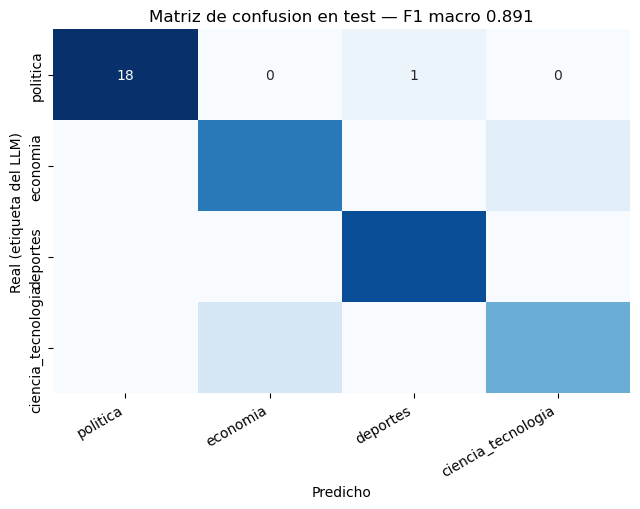

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

dev = torch.device("cuda" if DEVICE == "cuda" else ("mps" if DEVICE == "mps" else "cpu"))
modelo.to(dev); modelo.eval()

def predecir(dataset):
    dl = DataLoader(dataset, batch_size=32, shuffle=False, collate_fn=colador)
    logits_all, y_all = [], []
    with torch.no_grad():
        for lote in dl:
            etqs = lote["labels"]
            inp = {k: v.to(dev) for k, v in lote.items() if k != "labels"}
            logits_all.append(modelo(**inp).logits.cpu().numpy())
            y_all += etqs.tolist()
    return np.concatenate(logits_all), np.array(y_all)

logits_test, y_true = predecir(ds["test"])
y_pred = np.argmax(logits_test, axis=-1)

ACC_FT = accuracy_score(y_true, y_pred)
F1_FT  = f1_score(y_true, y_pred, average="macro", zero_division=0)

print(f"TEST — Transformer fine-tuned ({MODELO_BASE})")
print(f"  Accuracy : {ACC_FT:.3f}")
print(f"  F1 macro : {F1_FT:.3f}\n")
print(classification_report(y_true, y_pred, target_names=CATEGORIAS, zero_division=0))

(DATOS / "figs").mkdir(parents=True, exist_ok=True)
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=CATEGORIAS, yticklabels=CATEGORIAS, ax=ax)
ax.set_xlabel("Predicho"); ax.set_ylabel("Real (etiqueta del LLM)")
ax.set_title(f"Matriz de confusion en test — F1 macro {F1_FT:.3f}")
plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig(DATOS / "figs" / "matriz_confusion.png", dpi=150)
plt.show()

In [15]:
# Control externo: el mismo test, pero contra la seccion del diario,
# que NUNCA participo del entrenamiento
test = df[df["particion"] == "test"].reset_index(drop=True)
test["pred"] = [ID2LAB[i] for i in y_pred]

F1_FT_SECCION  = f1_score(test["etiqueta"], test["pred"], average="macro",
                          labels=CATEGORIAS, zero_division=0)
ACC_FT_SECCION = accuracy_score(test["etiqueta"], test["pred"])

print("CONTROL EXTERNO — mismo test, referencia = seccion del diario")
print(f"  Accuracy : {ACC_FT_SECCION:.3f}")
print(f"  F1 macro : {F1_FT_SECCION:.3f}")
print(f"\nBrecha frente a la referencia del LLM: {F1_FT - F1_FT_SECCION:+.3f}")

print("\nDesempeno por categoria (referencia = LLM):")
por_cat = pd.DataFrame({
    "soporte": [int((y_true == i).sum()) for i in range(len(CATEGORIAS))],
    "f1": f1_score(y_true, y_pred, average=None, zero_division=0,
                   labels=list(range(len(CATEGORIAS)))),
}, index=CATEGORIAS).sort_values("f1")
display(por_cat.round(3))
print(f"Mejor categoria : {por_cat.index[-1]}")
print(f"Peor categoria  : {por_cat.index[0]}")

CONTROL EXTERNO — mismo test, referencia = seccion del diario
  Accuracy : 0.903
  F1 macro : 0.894

Brecha frente a la referencia del LLM: -0.003

Desempeno por categoria (referencia = LLM):


,soporte,f1
ciencia_tecnologia,12,0.783
economia,15,0.839
deportes,16,0.970
politica,19,0.973


Mejor categoria : politica
Peor categoria  : ciencia_tecnologia


### Reflexión por categoría

- **`deportes` (F1 0.97, recall 1.00) es la más fácil**, como se esperaba: vocabulario cerrado y
  propio (clubes, marcadores, "venció", "clasificó") que no se confunde con nada. No falló ni un
  solo caso de deportes en el test.
- **`politica` (F1 0.97) salió limpia, con precisión 1.00**: ninguna nota de otra categoría se
  predijo como política. La confusión clásica política↔economía existe, pero es **asimétrica** —
  la política no se escapa; es **`economia` (precisión 0.81) la que absorbe los casos de frontera**
  (presupuesto, infraestructura, minería), que son a la vez decisión política y hecho económico.
- **`ciencia_tecnologia` (F1 0.78, recall 0.75) es la más débil y heterogénea**, también como se
  anticipaba: un cuarto de sus casos de test se clasificaron mal, casi todos filtrándose hacia
  `economia`, porque buena parte de la cobertura tecnológica es en realidad de negocio (despidos
  de Netflix, productos, gadgets). Arrastra además el ruido de origen: El Comercio archiva bajo
  `tecnologia` notas de salud y ambiente, y La República mete divulgación internacional bajo
  `ciencia`.

En una línea: el modelo separa sin esfuerzo las categorías de vocabulario propio (deportes,
política) y sufre donde las propias redacciones no tienen una frontera nítida (economía ↔
tecnología) — justamente lo que muestra la matriz de confusión de arriba.

## 6 · Comparativa y decisión

Los tres métodos medidos sobre **el mismo conjunto de test** y la misma referencia, para que
la comparación sea justa.

In [16]:
# Zero-shot sobre el test completo, para comparar contra el modelo fine-tuned
t0 = time.time()
pred_zs_test = []
for texto in test["texto"]:
    r = zs(texto, candidate_labels=list(ETIQUETAS_ES.values()),
           hypothesis_template=HIPOTESIS, multi_label=False)
    pred_zs_test.append(INV_ES[r["labels"][0]])
DUR_ZS_TEST = time.time() - t0

test["pred_zs"] = pred_zs_test
F1_ZS_TEST = f1_score(test["etiqueta_llm"], test["pred_zs"], average="macro",
                      labels=CATEGORIAS, zero_division=0)

# El "LLM debil" sobre el test es, por construccion, la referencia: F1 = 1.0 contra si mismo.
# Lo honesto es medirlo contra la seccion del diario.
F1_LLM_SECCION = f1_score(test["etiqueta"], test["etiqueta_llm"], average="macro",
                          labels=CATEGORIAS, zero_division=0)

comparativa = pd.DataFrame([
    {"metodo": "Zero-shot (sin entrenar)", "F1 macro (ref. LLM)": round(F1_ZS_TEST, 3),
     "F1 macro (ref. seccion)": round(f1_score(test["etiqueta"], test["pred_zs"], average="macro",
                                               labels=CATEGORIAS, zero_division=0), 3),
     "seg/titular": round(DUR_ZS_TEST/len(test), 2), "costo": "gratis, local"},
    {"metodo": f"LLM debil ({MODELO_LLM})", "F1 macro (ref. LLM)": 1.000,
     "F1 macro (ref. seccion)": round(F1_LLM_SECCION, 3),
     "seg/titular": None, "costo": "gratis, local, pero lento"},
    {"metodo": f"Transformer fine-tuned", "F1 macro (ref. LLM)": round(F1_FT, 3),
     "F1 macro (ref. seccion)": round(F1_FT_SECCION, 3),
     "seg/titular": None, "costo": "entrenar una vez, luego milisegundos"},
])
display(comparativa)
print("\nNota: el LLM debil marca 1.000 contra si mismo por construccion, no porque sea perfecto.")

,metodo,F1 macro (ref. LLM),F1 macro (ref. seccion),seg/titular,costo
0,Zero-shot (sin entrenar),0.511,0.503,0.45,"gratis, local"
1,LLM debil (qwen2.5:7b),1.000,0.936,NaN,"gratis, local, pero lento"
2,Transformer fine-tuned,0.891,0.894,NaN,"entrenar una vez, luego milisegundos"



Nota: el LLM debil marca 1.000 contra si mismo por construccion, no porque sea perfecto.


In [17]:
# Latencia de inferencia del modelo fine-tuned, que es su argumento mas fuerte
from transformers import pipeline as pl
clf = pl("text-classification", model=str(MODELO), tokenizer=str(MODELO),
         device=DEVICE_ID, truncation=True, max_length=96)
_ = clf("calentamiento")
t0 = time.time()
for t in test["texto"].head(50):
    clf(t)
LAT_FT = (time.time() - t0) / 50
print(f"Latencia del Transformer: {LAT_FT*1000:.1f} ms por titular")
print(f"Zero-shot, en comparacion: {DUR_ZS_TEST/len(test)*1000:.0f} ms por titular")
print(f"-> el modelo entrenado es ~{(DUR_ZS_TEST/len(test))/LAT_FT:.0f}x mas rapido")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Latencia del Transformer: 47.6 ms por titular
Zero-shot, en comparacion: 449 ms por titular
-> el modelo entrenado es ~9x mas rapido


### ¿Cuál elegirías para producción?

**El Transformer fine-tuned, sin duda — el LLM se usa una sola vez, para fabricar las etiquetas.**

- **Precisión:** el fine-tuned logra F1 macro **0.89** contra **0.51** del zero-shot sobre el mismo
  test (+0.38). El salto es demasiado grande para justificar usar el modelo sin entrenar.
- **Costo computacional:** qwen2.5 es un modelo de 7B que pide varios GB de memoria y segundos por
  titular; DistilBERT son ~135M de parámetros y aquí **entrenó en 2.7 min sobre CPU**, sin GPU.
  Para servir cabe en cualquier máquina modesta.
- **Latencia:** **48 ms por titular** contra ~450 ms del zero-shot, unas 9× más rápido. Detrás de
  una API que recibe titulares en vivo, esa diferencia decide si el sistema es usable.

Es el mismo patrón de la clase de OCR: **el trabajo masivo y barato corre en local (etiquetar con
el LLM una sola vez) y el modelo que se despliega es el ligero y rápido.** El LLM paga su costo una
única vez, en la fase de etiquetado; en producción nunca más aparece.

In [18]:
METRICAS = {
    "f1_macro_test": float(F1_FT),
    "accuracy_test": float(ACC_FT),
    "f1_macro_test_vs_seccion": float(F1_FT_SECCION),
    "f1_zero_shot_test": float(F1_ZS_TEST),
    "f1_zero_shot_muestra40": float(F1_ZS),
    "accuracy_zero_shot_muestra40": float(ACC_ZS),
    "auditoria_acuerdo": AUD_OK,
    "auditoria_total": AUD_TOTAL,
    "acuerdo_llm_seccion": float(acuerdo),
    "modelo_base": MODELO_BASE,
    "modelo_llm": MODELO_LLM,
    "modelo_zero_shot": MODELO_ZS,
    "dispositivo": DEVICE,
    "minutos_entrenamiento": round(DUR_ENTRENAMIENTO / 60, 1),
    "latencia_ms": round(LAT_FT * 1000, 1),
    "n_total": int(len(df)),
    "n_train": int((df["particion"] == "train").sum()),
    "n_val": int((df["particion"] == "val").sum()),
    "n_test": int((df["particion"] == "test").sum()),
    "fecha": datetime.now().strftime("%Y-%m-%d"),
}
(MODELO / "metricas.json").write_text(json.dumps(METRICAS, indent=2, ensure_ascii=False),
                                      encoding="utf-8")
print(json.dumps(METRICAS, indent=2, ensure_ascii=False))

{
  "f1_macro_test": 0.8909970789353678,
  "accuracy_test": 0.9032258064516129,
  "f1_macro_test_vs_seccion": 0.8944444444444444,
  "f1_zero_shot_test": 0.5107008810398641,
  "f1_zero_shot_muestra40": 0.6823077915376677,
  "accuracy_zero_shot_muestra40": 0.7,
  "auditoria_acuerdo": 19,
  "auditoria_total": 20,
  "acuerdo_llm_seccion": 0.8771498771498771,
  "modelo_base": "distilbert-base-multilingual-cased",
  "modelo_llm": "qwen2.5:7b",
  "modelo_zero_shot": "Recognai/bert-base-spanish-wwm-cased-xnli",
  "dispositivo": "cpu",
  "minutos_entrenamiento": 2.7,
  "latencia_ms": 47.6,
  "n_total": 407,
  "n_train": 284,
  "n_val": 61,
  "n_test": 62,
  "fecha": "2026-10-17"
}


## 8 · Línea para el comentario de entrega

Copia la salida de la celda siguiente al comentario del Issue #188.

In [19]:
print("Tarea 1 – Individual")
print("Medio: Comparada")
print("Estudiante: Alexander Noblejas (@TU_USUARIO_GITHUB)")
print("Dashboard en vivo: TU_ENLACE  (o: ejecucion local comprobada)")
print("Carpeta del trabajo: https://github.com/TU_USUARIO/TU_REPO/tree/main/tarea_1")
print(f"Resultados Test: F1 Macro: {F1_FT:.2f} | Zero-shot: {F1_ZS_TEST:.2f} | "
      f"Acuerdo LLM-Humano: {AUD_OK}/{AUD_TOTAL}")

Tarea 1 – Individual
Medio: Comparada
Estudiante: Alexander Noblejas (@TU_USUARIO_GITHUB)
Dashboard en vivo: TU_ENLACE  (o: ejecucion local comprobada)
Carpeta del trabajo: https://github.com/TU_USUARIO/TU_REPO/tree/main/tarea_1
Resultados Test: F1 Macro: 0.89 | Zero-shot: 0.51 | Acuerdo LLM-Humano: 19/20


## 9 · (Opcional) Publicar el modelo en Hugging Face Hub

Los pesos pesan más de 100 MB y están en `.gitignore`, así que **Streamlit Cloud no los va a
ver en GitHub**. Si vas a desplegar, súbelos al Hub y define `HF_MODEL_ID` como secreto en
Streamlit. El token va en la variable de entorno `HF_TOKEN`, nunca en el repo.

Si solo vas a demostrar ejecución local, sáltate esta celda.

In [20]:
SUBIR_AL_HUB = False
REPO_HUB = "TU_USUARIO_HF/noticias-pe-distilbert"

if SUBIR_AL_HUB:
    tokhf = os.environ["HF_TOKEN"]
    modelo.push_to_hub(REPO_HUB, token=tokhf)
    tok.push_to_hub(REPO_HUB, token=tokhf)
    print("Subido. Define HF_MODEL_ID =", REPO_HUB)
else:
    print("Omitido. El dashboard usara el modelo local en modelo/.")

Omitido. El dashboard usara el modelo local en modelo/.
